In [3]:
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.sparse.linalg import cg as sp_cg

import pandas as pd

from trips.test_problems.Tomography import Tomography
import astra

import jlinops

import numpy as np
import math

from jlinops.base import _CustomLinearOperator
# from .util import get_device

# from ias import IASSolver

from trips.utilities.phantoms import shepp_logan

from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec
# mpl.rcParams['text.usetex'] = True
# mpl.rc('text.latex', preamble=r'\usepackage{amsmath}')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])

method_markers = {
    "GKS": "o",
    "S-GKS": "o",
    "resS-GKS": "v",
    "recS-GKS": "^",
    "PS-GKS": "o",
    "resPS-GKS": "v",
    "recPS-GKS": "^",
    "PS-GKB": "o",
    "FGK": "o",
    "FLSQR-I": "$\\text{I}$",
    "FLSQR-R": "$\\text{R}$",
    "FLSQR-W": "$*$",
    "IRW-FLSQR": "x",
}

method_colors = {
    "GKS": "C1",
    "S-GKS": "C4",
    "resS-GKS": "C4",
    "recS-GKS": "C4",
    "PS-GKS": "C2",
    "resPS-GKS": "C2",
    "recPS-GKS": "C2",
    "PS-GKB": "C5",
    "FGK": "C3",
    "FLSQR-I": "C3",
    "FLSQR-R": "C3",
    "FLSQR-W": "C3",
    "IRW-FLSQR": "C3",
}

method_lines = {
    "GKS": "solid",
    "S-GKS": "solid",
    "resS-GKS": "dotted",
    "recS-GKS": "dashed",
    "PS-GKS": "solid",
    "resPS-GKS": "dotted",
    "recPS-GKS": "dashed",
    "PS-GKB": "solid",
    "FGK": "solid",
    "FLSQR-I": "solid",
    "FLSQR-R": "solid",
    "FLSQR-W": "solid",
    "IRW-FLSQR": "solid",
}



from PIL import Image
import numpy as np

CMAP = "gray"

import sys
import os

# Go three directories up
current_dir = os.path.dirname(os.getcwd())
three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
sys.path.append(three_dirs_up)


from msolver import MM2019GKS, IASGKS, VanillaGKS, MMGKS, MM3GKS, MM2GKS, MMXGKS
from fsolver import IASFGK, MM2019FGK, MMFGK, MM3FGK, MMXFGK # VanillaFK
from pgkbsolver import MM2019GKB, IASGKB, MMGKB, MM3GKB, MMXGKB
from f2019solver import MM2019FGK2019, IASFGK2019

from pinv import CGWeightedNeumann2DPinvOperatorGPU

/home/jlindbloom/miniconda3/envs/jlinops/lib/python3.11/site-packages/cupyx/jit/_interface.py:173: FutureWarning: cupyx.jit.rawkernel is experimental. The interface can change in the future.
  cupy._util.experimental('cupyx.jit.rawkernel')


# Setup problem

In [4]:
np.random.seed(0)
theta_max = np.pi
#Tomo = Tomography (geom="fanflat", CommitCrime=True, theta_max=theta_max)
#Tomo = Tomography (geom="fanflat", CommitCrime=True)
Tomo = Tomography (geom="parallel", CommitCrime=False, theta_max=theta_max)
views = 28
noise_percent = 0.01 # percent of maximum of noiseless signal A x_true
N = 256

x_true = shepp_logan(N)
img_shape = x_true.shape
nx, ny = x_true.shape
(F , b_true , p , q , AforMatrixOperation ) = Tomo.gen_data( x_true , nx , ny , views )

noise_stdev = noise_percent*np.amax(b_true)
noise_var = noise_stdev**2
print(f"Noise level: {noise_percent}")
print(f"Noise stdev: {noise_stdev}")
print(f"Noise var: {noise_var}")


b_noisy = b_true.flatten() + noise_stdev*np.random.normal(size=b_true.flatten().shape)
b_noisy_shaped = b_noisy.reshape((p,q))
noisy_signal = b_noisy.flatten()
m, n = F.shape


# Define linear operator implementing A
_matvec_fn = lambda x: F.matvec(x)
_rmatvec_fn = lambda x: F.rmatvec(x)
A = _CustomLinearOperator( (m,n), _matvec_fn, _rmatvec_fn, device="cpu")

# Underdetermined rate:
underdetermined_rate = noisy_signal.size/(nx*ny)
print(f"Underdetermined rate: {underdetermined_rate}")

settings
no crime
Noise level: 0.01
Noise stdev: 0.6781836700439453
Noise var: 0.4599330903142749
Underdetermined rate: 0.1546630859375


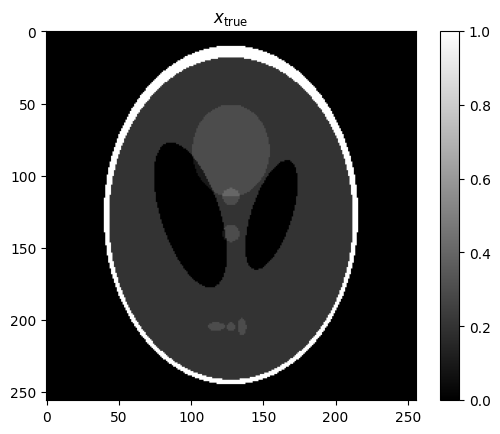

In [5]:
plt.imshow(x_true.reshape((nx,ny)), cmap=CMAP)
plt.title("$x_{\\text{true}}$")
plt.colorbar()
plt.show()

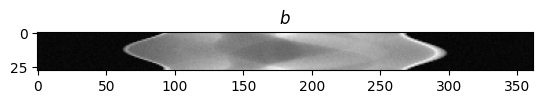

In [6]:
plt.imshow(b_noisy_shaped, cmap=CMAP)
plt.title("$b$")
plt.show()

# Setup prior

In [7]:
# Set method
Lmat = jlinops.build_neumann2d_sparse_matrix(img_shape)
L = jlinops.Neumann2D(img_shape)

# # Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     delta = 1e-15
#     for j in range(10):
#         try:
#             return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=delta)
#         except:
#             delta *= 10
#     return None

K = np.ones(n)/np.linalg.norm(np.ones(n))
K = jlinops.MatrixLinearOperator(K)


def Lpinv_factory(w, *args, **kwargs):
    return CGWeightedNeumann2DPinvOperatorGPU(img_shape, weights=w, tol=1e-4, *args, **kwargs)


# mm_weight_params_2019 = {
#     "q": 1.0,
#     "tau1": 1e-10,
#     "tau2": 1e-16,
# }

mm2_weight_params = {
    "q": 1.0,
}

mm3_weight_params = {
    "q": 1.0,
}

mm_weight_params = {
    "q": 1.0,
    "epsilon": 1e-4,
}

mmxx_weight_params = {
    "q": 1.0,
    "epsilon": 1e-10,
}

ias_weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}

# Setup solvers

In [8]:
# Build solvers
gks_solver = VanillaGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

mm_gks_solver = MMGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm2_gks_solver = MM2GKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm3_gks_solver = MM3GKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmx_gks_solver = MMXGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm_fgk_solver = MMFGK(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmx_fgk_solver = MMXFGK(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmxx_fgk_solver = MMFGK(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm_gkb_solver = MMGKB(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmx_gkb_solver = MMXGKB(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

ias_gks_solver = IASGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
ias_fgk_solver = IASFGK(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
ias_gkb_solver = IASGKB(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

# Misc
AK = A @ K.A
AKpinv = jlinops.QRPinvOperator(AK)
xker = K @ (AKpinv @ b_noisy)

# Run all solvers

In [12]:
# Parameters
method = "dp"
n_its = 100
n_its_recres = 300
restart_dim = 40
rec_max_dim = 40
rec_min_dim = 25
ksparsity = None
lambdah_min = 1e-7
lambdah_max = 1e7
fgk_breakdown_tol = 1e-15

In [10]:
%%capture 

all_v_results = []

# GKS
v_gks_data = gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params={},
                                    regparam_kwargs={"eta":1.01})

all_v_results.append( ( "V", "GKS", v_gks_data  ) )


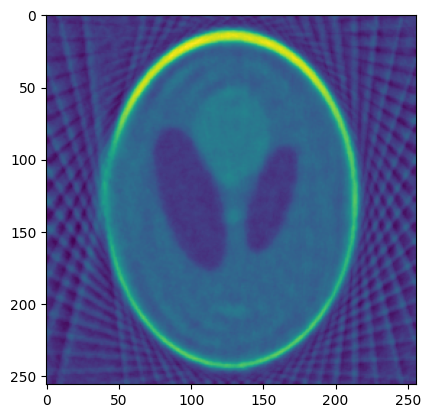

In [11]:
plt.imshow(v_gks_data["x"].reshape(img_shape))

In [10]:
all_mm_results = []

# S-GKS
mm_sgks_data = mmx_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params=mm2_weight_params,
                                    regparam_kwargs={"eta":1.01})

all_mm_results.append( ( "MM", "S-GKS", mm_sgks_data  ) )

# Recycled S-GKS
mm_ressgks_data = mmx_gks_solver.solve(n_iter=n_its_recres, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params=mm2_weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=None, min_dim=rec_min_dim, max_dim=rec_max_dim)

all_mm_results.append( ( "MM", "S-GKS (restarted)", mm_ressgks_data  ) )

# Restarted S-GKS
mm_recsgks_data = mmx_gks_solver.solve(n_iter=n_its_recres, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params=mm2_weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=restart_dim)

all_mm_results.append( ( "MM", "S-GKS (recycled)", mm_recsgks_data  ) )


# PS-GKS
mm_psgks_data = mmx_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=mm_weight_params,
                                                 regparam_kwargs={"eta":1.01})

all_mm_results.append( ( "MM", "PS-GKS", mm_psgks_data  ) )


# Restarted PS-GKS
mm_respsgks_data = mmx_gks_solver.solve_with_priorconditioning(n_iter=n_its_recres, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=mm_weight_params, restart_dim=restart_dim,
                                                 regparam_kwargs={"eta":1.01})

all_mm_results.append( ( "MM", "PS-GKS (restarted)", mm_respsgks_data  ) )


# Recycled PS-GKS
mm_recpsgks_data = mmx_gks_solver.solve_with_priorconditioning(n_iter=n_its_recres, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=mm_weight_params, min_dim=rec_min_dim, max_dim=rec_max_dim,
                                                 regparam_kwargs={"eta":1.01})

all_mm_results.append( ( "MM", "PS-GKS (recycled)", mm_recpsgks_data  ) )


# PS-GKB solver
mm_gkb_data = mmx_gkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=x_true.flatten(), ksparsity=None, weight_params=mm_weight_params,
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )
all_mm_results.append( ( "MM", "PS-GKB", mm_gkb_data  ) )


# FGK solver
mmxx_fgk_data = mmx_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=x_true.flatten(), ksparsity=None, weight_params=mmxx_weight_params, refresh_basis=False, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

all_mm_results.append( ( "MM", "FGK", mmxx_fgk_data  ) )



Augmented basis with initial guess!


9.231850930294137
9.045757915166691
9.21851173059584
9.357020792524995
9.742135716820691
10.304705870177258
10.611063589985477
10.720133580310238
10.712566114713184
10.70090199686749
10.989024164092172
11.104793486558528
11.114981152802928
11.073308795439452
10.996339991947636
10.895226736228436
10.811865862573313
10.749100844369115
10.681869482238248
10.630859986137732
10.592835257041402
10.564422495520207
10.543633791372423
10.525962583466827
10.515420184966144
10.50571869658076
10.494259261829708
10.485358694554353
10.478920346449987
10.470748115327176
10.461141092447036
10.459505273609185
10.464497222316378
10.467803833433015
10.47019039569115
10.471278989668633
10.476317630746797
10.487126980886467
10.490230653728474
10.488097046298256
10.486906725354837
10.483632467744531
10.480607764169534
10.475908869929556
10.474889155229569
10.487167192269142
10.48301606194675
10.493335325317823
10.491361860656955
10.49512931291878
10.525643267755115
10.559049478801287
10.551483272245234
10.5

9.231850930294137
9.045757915166691
9.21851173059584
9.357020792524995
9.742135716820691
10.304705870177258
10.611063589985477
10.720133580310238
10.712566114713184
10.70090199686749
10.989024164092172
11.104793486558528
11.114981152802928
11.073308795439452
10.996339991947636
10.895226736228436
10.811865862573313
10.749100844369115
10.681869482238248
10.630859986137732
10.592835257041402
10.564422495520207
10.543633791372423
10.525962583466827
(30, 30)
(30, 30)
(60, 30)
10.520101453474517
10.469665287394427
9.904764956163739
10.326838229134037
10.582293035040701
10.684630287440285
10.530062345780694
10.527158074484133
10.536374957421978
10.56223884113826
10.568589609679902
10.584582827161924
10.585808496108612
10.574796205906496
10.59312918364767
(30, 30)
(30, 30)
(60, 30)
10.593717211364796
10.59612495513881
10.613791494588238
10.606706467998842
10.614524985876368
10.608921359815028
10.609582735696156
10.597791264806842
10.611856094135469
10.540570316954545
10.519080583652839
10.5031

9.231850930294137
9.045757915166691
9.21851173059584
9.357020792524995
9.742135716820691
10.304705870177258
10.611063589985477
10.720133580310238
10.712566114713184
10.70090199686749
10.989024164092172
11.104793486558528
11.114981152802928
11.073308795439452
10.996339991947636
10.895226736228436
10.811865862573313
10.749100844369115
10.681869482238248
10.630859986137732
10.592835257041402
10.564422495520207
10.543633791372423
10.525962583466827
10.526507386123868
10.518959520063673
8.11470002489265
7.925349470690651
7.937119466458419
8.08676745681877
8.13405219747648
8.110071718957636
8.099815467814938
8.05304748582733
8.038878636640607
8.021212525347387
8.005182094938084
7.9989770036991406
8.02048221216836
8.010969587887537
8.047334738881235
8.099452050871113
8.055808059322379
8.04867064223857
8.047651264564143
8.044205049976156
8.04551787877668
8.042068471266909
8.040450025392431
8.036719347647683
8.027581404504916
8.007714154803073
7.987701493384498
7.981881974371187
8.0137352986878

/home/jlindbloom/Github/IRLS_prec_GSBL/paper_examples/2d_tomo_shepp/../../msolver.py:888: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


...

0.6917567275383217
Starting iteration 98


/home/jlindbloom/Github/IRLS_prec_GSBL/paper_examples/2d_tomo_shepp/../../fsolver.py:566: UserWarning: V appears to no longer be semi-orthogonal, failes test with value: 9.450802124801951e-06.
  warnings.warn(f"V appears to no longer be semi-orthogonal, failes test with value: {V_test}.", UserWarning)
/home/jlindbloom/Github/IRLS_prec_GSBL/paper_examples/2d_tomo_shepp/../../fsolver.py:571: UserWarning: U appears to no longer be semi-orthogonal, fails test with value 7.547776507871442e-07.
  warnings.warn(f"U appears to no longer be semi-orthogonal, fails test with value {U_test}.", UserWarning)


0.737865358421321
Starting iteration 99


/home/jlindbloom/Github/IRLS_prec_GSBL/paper_examples/2d_tomo_shepp/../../fsolver.py:566: UserWarning: V appears to no longer be semi-orthogonal, failes test with value: 9.469888767195053e-06.
  warnings.warn(f"V appears to no longer be semi-orthogonal, failes test with value: {V_test}.", UserWarning)
/home/jlindbloom/Github/IRLS_prec_GSBL/paper_examples/2d_tomo_shepp/../../fsolver.py:571: UserWarning: U appears to no longer be semi-orthogonal, fails test with value 7.592265973724231e-07.
  warnings.warn(f"U appears to no longer be semi-orthogonal, fails test with value {U_test}.", UserWarning)


0.7810353797316982


In [11]:
all_ias_results = []

# S-GKS
ias_sgks_data = ias_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01})

all_ias_results.append( ( "IAS", "S-GKS", ias_sgks_data  ) )

# Restarted S-GKS
ias_ressgks_data = ias_gks_solver.solve(n_iter=n_its_recres, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=None, min_dim=rec_min_dim, max_dim=rec_max_dim)

all_ias_results.append( ( "IAS", "S-GKS (restarted)", ias_ressgks_data  ) )

# Recycled S-GKS
ias_recsgks_data = ias_gks_solver.solve(n_iter=n_its_recres, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=restart_dim)

all_ias_results.append( ( "IAS", "S-GKS (recycled)", ias_recsgks_data  ) )


# PS-GKS
ias_psgks_data = ias_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                                 regparam_kwargs={"eta":1.01})

all_ias_results.append( ( "IAS", "PS-GKS", ias_psgks_data  ) )


# Restarted PS-GKS
ias_respsgks_data = ias_gks_solver.solve_with_priorconditioning(n_iter=n_its_recres, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params, restart_dim=restart_dim,
                                                 regparam_kwargs={"eta":1.01})

all_ias_results.append( ( "IAS", "PS-GKS (restarted)", ias_psgks_data  ) )


# Recycled PS-GKS
ias_recpsgks_data = ias_gks_solver.solve_with_priorconditioning(n_iter=n_its_recres, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params, min_dim=rec_min_dim, max_dim=rec_max_dim,
                                                 regparam_kwargs={"eta":1.01})

all_ias_results.append( ( "IAS", "PS-GKS (recycled)", ias_recpsgks_data  ) )


# PS-GKB solver
ias_gkb_data = ias_gkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=x_true.flatten(), ksparsity=None, weight_params=ias_weight_params,
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )
all_ias_results.append( ( "IAS", "PS-GKB", ias_gkb_data  ) )


# FGK solver
ias_fgk_data = ias_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=x_true.flatten(), ksparsity=None, weight_params=ias_weight_params, refresh_basis=False, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

all_ias_results.append( ( "IAS", "FGK", ias_fgk_data  ) )



Augmented basis with initial guess!


62.59267652133999
79.68689896960282
87.2002849087344
95.64924787733077
106.13854779914134
116.68224510269494
127.99423568575762
140.04498499567111
150.65718423474138
161.00251296072366
171.54553319820943
183.24234421002456
192.41797631027583
199.3623861816052
207.5544855411793
215.05778454885237
220.2576662860639
226.13239800143788
230.8888164503432
232.7884492202726
236.05526053957587
239.36237457162505
241.17367442558566
243.41689885508453
244.67824501666277
246.40716881038816
247.55315452400055
248.0227740879564
248.47443455860244
248.73091816325567
248.86108915660756
248.8703415274701
248.996785725389
249.03322239396493
249.0506374343296
249.16716355894147
249.1828502103685
249.20114184599615
249.24668268574973
249.2390627880274
249.24463875549276
249.2636001859254
249.2516862069617
249.20902942822488
249.20364353483055
249.1987355092763
249.10996203605657
248.86842558528983
249.01503519970802
248.89093106329108
248.70951878327492


248.55394011779956
248.4029536808598
248.25165603658562
247.86833433192854
247.580735071713
247.20209016868802
246.81911038416484
246.46646794760815
246.2170581057408
245.97802171408816
245.7908113327427
245.6559123133066
245.64048639141777
245.47391099204214
245.44851683131762
245.37687868669025
245.3207211930052
245.25814167412227
245.1790363791093
245.11186680715593
245.0431607493907
244.98616131242878
244.94125503832296
244.89553640940235
244.90014593412138
244.89093434005025
244.90138255066978
244.90864618493
244.91396495490824
244.9057300289645
244.8904219636447
244.8777679515578
244.8572281917922
244.83039514326762
244.8035200633492
244.78017355723603
244.999863652389
244.81513814730616
244.97252510384635
245.0796968636339
245.191103916128
245.20612580860796
245.23569219142922
244.94774159163703
245.57941675455797
245.7687129872066
246.01443089601062
246.27107832960823
246.60381934579837
Augmented basis with initial guess!


62.59267652133999
79.68689896960282
87.2002849087344
95.64924787733077
106.13854779914134
116.68224510269494
127.99423568575762
140.04498499567111
150.65718423474138
161.00251296072366
171.54553319820943
183.24234421002456
192.41797631027583
199.3623861816052
207.5544855411793
215.05778454885237
220.2576662860639
226.13239800143788
230.8888164503432
232.7884492202726
236.05526053957587
239.36237457162505
241.17367442558566
243.41689885508453
(30, 30)
(30, 30)
(60, 30)
249.82230491951012
255.75527428221628
206.15896743840082
217.4872155329125
219.42364978507257
222.74220630702797
228.70023574739392
242.71825023214316
249.16283506835606
255.92036305547012
263.21903889310704
271.35803876277436
284.1444817775913
297.0942705730203
308.86501926183814
(30, 30)
(30, 30)
(60, 30)
310.04442492975363
328.8404105204357
382.0813808567551
367.1088204896192
376.3817356000588
383.264283707677
395.49972478990173
411.6987799806247
437.69193310378813
462.68633989599874
485.4428724112274
502.0190086127571

62.59267652133999
79.68689896960282
87.2002849087344
95.64924787733077
106.13854779914134
116.68224510269494
127.99423568575762
140.04498499567111
150.65718423474138
161.00251296072366
171.54553319820943
183.24234421002456
192.41797631027583
199.3623861816052
207.5544855411793
215.05778454885237
220.2576662860639
226.13239800143788
230.8888164503432
232.7884492202726
236.05526053957587
239.36237457162505
241.17367442558566
243.41689885508453
244.88118100065176
278.8204168990885
243.9844385174619
231.42721742545714
266.449237840057
283.43132942842686
291.6604558854516
307.149008591069
331.13911143900816
348.53019735557785
370.47604655492415
381.5661709932485
401.8487142479543
417.45903875922403
435.2134037659065
461.32504820380694
488.02183793358716
514.9996274850469
532.6248434071779
552.6430841541498
571.2471628052142
583.8369044383829
600.7225545646573
616.1439100429702
627.432153957296
635.1203932093541
641.1233108727541
645.2516917142299
649.1773724450583
650.8150939993192
684.9512

...

33.95175930578592
Starting iteration 98


/home/jlindbloom/Github/IRLS_prec_GSBL/paper_examples/2d_tomo_shepp/../../fsolver.py:566: UserWarning: V appears to no longer be semi-orthogonal, failes test with value: 8.757760029762085e-06.
  warnings.warn(f"V appears to no longer be semi-orthogonal, failes test with value: {V_test}.", UserWarning)
/home/jlindbloom/Github/IRLS_prec_GSBL/paper_examples/2d_tomo_shepp/../../fsolver.py:571: UserWarning: U appears to no longer be semi-orthogonal, fails test with value 7.515358865415353e-07.
  warnings.warn(f"U appears to no longer be semi-orthogonal, fails test with value {U_test}.", UserWarning)


34.08921269659766
Starting iteration 99


/home/jlindbloom/Github/IRLS_prec_GSBL/paper_examples/2d_tomo_shepp/../../fsolver.py:566: UserWarning: V appears to no longer be semi-orthogonal, failes test with value: 8.78881901392948e-06.
  warnings.warn(f"V appears to no longer be semi-orthogonal, failes test with value: {V_test}.", UserWarning)
/home/jlindbloom/Github/IRLS_prec_GSBL/paper_examples/2d_tomo_shepp/../../fsolver.py:571: UserWarning: U appears to no longer be semi-orthogonal, fails test with value 7.542061902408903e-07.
  warnings.warn(f"U appears to no longer be semi-orthogonal, fails test with value {U_test}.", UserWarning)


34.21751375575745


# Save and make tables

In [12]:
v_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "HaarPSI":[], "Gini index": [], "Hoyer index": [], "A matvecs": [], "L matvecs": [], "WLpinv matvecs": [], "n_iters": []   })

for set in all_v_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "HaarPSI":[ method_data["haar_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ] , "A matvecs": [ method_data["tot_matvec_A"] ], "L matvecs": [ method_data["tot_matvec_L"] ], "WLpinv matvecs": [ method_data["tot_matvec_WLpinv"] ], "n_iters": [ method_data["n_completed_iterations"] ]   })
        v_df = pd.concat([v_df, new_df], axis=0)


mm_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": []})

for set in all_mm_results:
        weight_str, method_label, method_data = set
        # print(method_label)
        # print(method_data["rre_history"][-1])
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "HaarPSI":[ method_data["haar_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ],  "A matvecs": [ method_data["tot_matvec_A"] ], "L matvecs": [ method_data["tot_matvec_L"] ], "WLpinv matvecs": [ method_data["tot_matvec_WLpinv"] ], "n_iters": [ method_data["n_completed_iterations"] ]   })
        mm_df = pd.concat([mm_df, new_df], axis=0)



ias_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": []})

for set in all_ias_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "HaarPSI":[ method_data["haar_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ],  "A matvecs": [ method_data["tot_matvec_A"] ], "L matvecs": [ method_data["tot_matvec_L"] ], "WLpinv matvecs": [ method_data["tot_matvec_WLpinv"] ], "n_iters": [ method_data["n_completed_iterations"] ]    })
        ias_df = pd.concat([ias_df, new_df], axis=0)



In [24]:
for item in all_mm_results:
    _, tmp, _ = item
    print(tmp)

S-GKS
S-GKS (restarted)
S-GKS (recycled)
PS-GKS
PS-GKS (restarted)
PS-GKS (recycled)
PS-GKB
FGK


In [13]:
# all_df = pd.concat([v_df, mm_df, ias_df])
# all_df = all_df.rename(columns={'lambdah': '$\lambda$'})
# all_df.to_csv("2d_tomo_shepp_performance_results.csv")
# all_df

all_df = pd.concat([v_df, mm_df, ias_df])
all_df = all_df[["Weights", "Method", "lambdah", "n_iters", "RRE", "SSIM", "Gini index", "A matvecs", "L matvecs", "WLpinv matvecs"]]
all_df = all_df.rename(columns={'lambdah': '$\lambda$', "n_iters":"$n_{\\textrm{iter}}$", "A matvecs":"$n_{\mathbf{A}}$", "L matvecs":"$n_{\mathbf{L}}$", "WLpinv matvecs":"$n_{\mathbf{ L }_k^\dagger }$"  })
all_df.to_csv("2d_tomo_shepp_performance_results.csv")
all_df

,Weights,Method,$\lambda$,$n_{\textrm{iter}}$,RRE,SSIM,Gini index,$n_{\mathbf{A}}$,$n_{\mathbf{L}}$,$n_{\mathbf{ L }_k^\dagger }$
0,V,GKS,1.552907e+02,100.0,0.417884,0.421747,0.538330,215.0,305.0,0.0
0,MM,S-GKS,1.061862e+01,100.0,0.350252,0.502165,0.695271,215.0,306.0,0.0
0,MM,S-GKS (restarted),8.877064e+00,300.0,0.362476,0.500118,0.699069,900.0,1191.0,0.0
0,MM,S-GKS (recycled),7.784979e+00,300.0,0.350476,0.518163,0.709800,625.0,916.0,0.0
0,MM,PS-GKS,1.709766e+01,100.0,0.151154,0.933854,0.957185,11111.0,103.0,11210.0
0,MM,PS-GKS (restarted),1.714150e+01,300.0,0.151294,0.933814,0.957079,8951.0,303.0,9250.0
0,MM,PS-GKS (recycled),1.710700e+01,300.0,0.150062,0.934404,0.957559,84542.0,303.0,84841.0
0,MM,PS-GKB,1.689113e+01,100.0,0.151705,0.933941,0.957594,10103.0,101.0,10200.0
0,MM,FGK,7.810354e-01,100.0,0.691787,0.137311,0.626662,203.0,201.0,200.0
0,IAS,S-GKS,2.466038e+02,100.0,0.290374,0.598176,0.721221,215.0,306.0,0.0


In [14]:
def scientific_to_latex(sci_str):
    # Split the number into base and exponent parts
    sci_str = f"{sci_str:.0e}"
    base, exponent = sci_str.split('e')
    
    # Convert base to integer (since the decimal places can be ignored)
    base = str(int(float(base)))
    
    # Prepare the exponent part, removing the leading "+" if it's a positive exponent
    exponent = exponent.lstrip("+")
    
    # Format the result as a LaTeX string
    latex_str = f"${base}\\cdot10^{{{int(exponent)}}}$"
    
    return latex_str

In [15]:
# print( all_df.to_latex(index=False, formatters={'$\lambda$': lambda s: scientific_to_latex(s), 
#                                                 "RRE": "${:.3f}$", "SSIM": "${:.3f}$", "HaarPSI": "${:.4e}$", 
#                                                   "Gini index": "${:.3f}$", "Hoyer index": "${:.3f}$"
#                                                     }) )

print( all_df.to_latex(index=False, formatters={'$\lambda$': lambda s: scientific_to_latex(s), 
                                                "RRE": "${:.3f}$", "SSIM": "${:.3f}$", 
                                                  "Gini index": "${:.3f}$", "Hoyer index": "${:.3f}$", 
                                                  "$n_{\\textrm{iter}}$": "${:.0f}$",
                                                  "$n_{\mathbf{A}}$": "${:.0f}$", "$n_{\mathbf{L}}$": "${:.0f}$", "$n_{\mathbf{ L }_k^\dagger }$": "${:.0f}$"
                                                    }) )

\begin{tabular}{llrrrrrrrr}
\toprule
Weights & Method & $\lambda$ & $n_{\textrm{iter}}$ & RRE & SSIM & Gini index & $n_{\mathbf{A}}$ & $n_{\mathbf{L}}$ & $n_{\mathbf{ L }_k^\dagger }$ \\
\midrule
V & GKS & $2\cdot10^{2}$ & $100$ & $0.418$ & $0.422$ & $0.538$ & $215$ & $305$ & $0$ \\
MM & S-GKS & $1\cdot10^{1}$ & $100$ & $0.350$ & $0.502$ & $0.695$ & $215$ & $306$ & $0$ \\
MM & S-GKS (restarted) & $9\cdot10^{0}$ & $300$ & $0.362$ & $0.500$ & $0.699$ & $900$ & $1191$ & $0$ \\
MM & S-GKS (recycled) & $8\cdot10^{0}$ & $300$ & $0.350$ & $0.518$ & $0.710$ & $625$ & $916$ & $0$ \\
MM & PS-GKS & $2\cdot10^{1}$ & $100$ & $0.151$ & $0.934$ & $0.957$ & $11111$ & $103$ & $11210$ \\
MM & PS-GKS (restarted) & $2\cdot10^{1}$ & $300$ & $0.151$ & $0.934$ & $0.957$ & $8951$ & $303$ & $9250$ \\
MM & PS-GKS (recycled) & $2\cdot10^{1}$ & $300$ & $0.150$ & $0.934$ & $0.958$ & $84542$ & $303$ & $84841$ \\
MM & PS-GKB & $2\cdot10^{1}$ & $100$ & $0.152$ & $0.934$ & $0.958$ & $10103$ & $101$ & $10200$ \\
MM & F

# Reconstruction plots

In [16]:
from skimage.metrics import structural_similarity

In [17]:
b_noisy

array([1.19635149, 0.27138008, 0.66376412, ..., 1.11557771, 0.34798291,
       0.22109433])

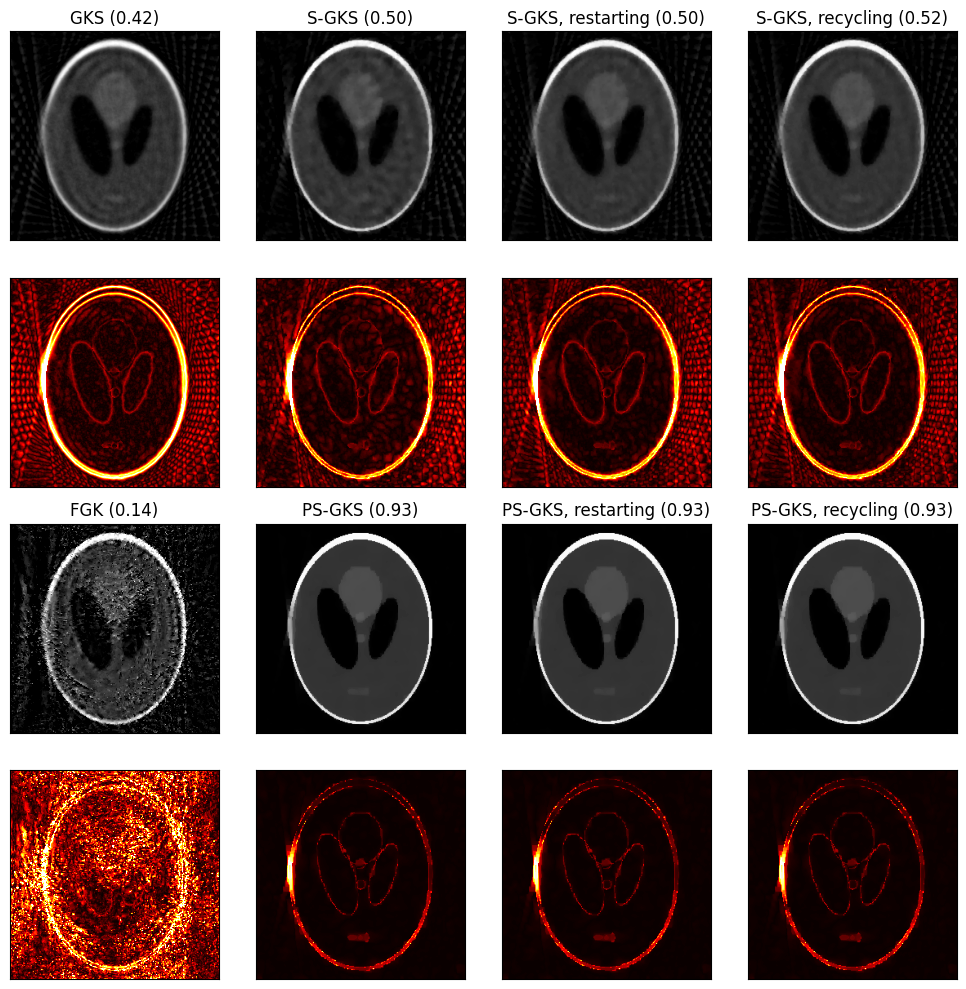

In [30]:
err_cmap = "hot"

vbound = 0.4
metric = "ssim_history"
ground_truth = x_true.copy()
b = noisy_signal.copy()

fig, axs = plt.subplots(4,4,figsize=(10,10))

# Observed
# perf_metric = structural_similarity( b.reshape(img_shape), ground_truth.reshape(img_shape), data_range=(np.amax(ground_truth) - np.amin(ground_truth) ), gaussian_weights=True, sigma=1.5, use_sample_covariance=False )
# axs[0,0].imshow(b.reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# axs[0,0].set_title(f"Data ({perf_metric:.2f})")
# axs[0,0].set_xticks([])
# axs[0,0].set_yticks([])

# axs[1,0].imshow(np.abs( b.reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[1,0].set_xticks([])
# axs[1,0].set_yticks([])


# V-GKS
axs[0,0].imshow(v_gks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = v_gks_data[metric][-1]
axs[0,0].set_title(f"GKS ({perf_metric:.2f})")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( v_gks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])

# FGK
axs[2,0].imshow(mm_fgk_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = mm_fgk_data[metric][-1]
axs[2,0].set_title(f"FGK ({perf_metric:.2f})")
axs[2,0].set_xticks([])
axs[2,0].set_yticks([])

axs[3,0].imshow(np.abs( mm_fgk_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,0].set_xticks([])
axs[3,0].set_yticks([])




# S-GKS
axs[0,1].imshow(mm_sgks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = mm_sgks_data[metric][-1]
axs[0,1].set_title(f"S-GKS ({perf_metric:.2f})")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( mm_sgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])



# PS-GKS
axs[2,1].imshow(mm_psgks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = mm_psgks_data[metric][-1]
axs[2,1].set_title(f"PS-GKS ({perf_metric:.2f})")
axs[2,1].set_xticks([])
axs[2,1].set_yticks([])

axs[3,1].imshow(np.abs( mm_psgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,1].set_xticks([])
axs[3,1].set_yticks([])




# S-GKS (restarted)
axs[0,2].imshow(mm_ressgks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = mm_ressgks_data[metric][-1]
axs[0,2].set_title(f"S-GKS, restarting ({perf_metric:.2f})")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( mm_ressgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])



# PS-GKS (restarted)
axs[2,2].imshow(mm_respsgks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = mm_respsgks_data[metric][-1]
axs[2,2].set_title(f"PS-GKS, restarting ({perf_metric:.2f})")
axs[2,2].set_xticks([])
axs[2,2].set_yticks([])

axs[3,2].imshow(np.abs( mm_respsgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,2].set_xticks([])
axs[3,2].set_yticks([])






# S-GKS (recycling)
axs[0,3].imshow(mm_recsgks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = mm_recsgks_data[metric][-1]
axs[0,3].set_title(f"S-GKS, recycling ({perf_metric:.2f})")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( mm_recsgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])



# PS-GKS (recycling)
axs[2,3].imshow(mm_recpsgks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = mm_recpsgks_data[metric][-1]
axs[2,3].set_title(f"PS-GKS, recycling ({perf_metric:.2f})")
axs[2,3].set_xticks([])
axs[2,3].set_yticks([])

axs[3,3].imshow(np.abs( mm_recpsgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,3].set_xticks([])
axs[3,3].set_yticks([])









# # PS-GKB
# axs[0,3].imshow(mm_psgkb_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# perf_metric = mm_psgkb_data[metric][-1]
# axs[0,3].set_title(f"PS-GKB ({perf_metric:.2f})")
# axs[0,3].set_xticks([])
# axs[0,3].set_yticks([])

# axs[1,3].imshow(np.abs( mm_psgkb_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[1,3].set_xticks([])
# axs[1,3].set_yticks([])



# # LSQR-I
# axs[2,1].imshow(mm_fgk2019I_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# perf_metric = mm_fgk2019I_data[metric][-1]
# axs[2,1].set_title(f"FLSQR-I ({perf_metric:.2f})")
# axs[2,1].set_xticks([])
# axs[2,1].set_yticks([])

# axs[3,1].imshow(np.abs( mm_fgk2019I_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[3,1].set_xticks([])
# axs[3,1].set_yticks([])



# # LSQR-R
# axs[2,2].imshow(mm_fgk2019R_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# perf_metric = mm_fgk2019R_data[metric][-1]
# axs[2,2].set_title(f"FLSQR-R ({perf_metric:.2f})")
# axs[2,2].set_xticks([])
# axs[2,2].set_yticks([])

# axs[3,2].imshow(np.abs( mm_fgk2019R_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[3,2].set_xticks([])
# axs[3,2].set_yticks([])


# # LSQR-W
# axs[2,3].imshow(mm_fgk2019W_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# perf_metric = mm_fgk2019W_data[metric][-1]
# axs[2,3].set_title(f"FLSQR-W ({perf_metric:.2f})")
# axs[2,3].set_xticks([])
# axs[2,3].set_yticks([])

# axs[3,3].imshow(np.abs( mm_fgk2019W_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[3,3].set_xticks([])
# axs[3,3].set_yticks([])




# # IRW-LSQR
# axs[2,4].imshow(mm_fgk2019IRW_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# perf_metric = mm_fgk2019IRW_data[metric][-1]
# axs[2,4].set_title(f"IRW-FLSQR ({perf_metric:.2f})")
# axs[2,4].set_xticks([])
# axs[2,4].set_yticks([])

# axs[3,4].imshow(np.abs( mm_fgk2019IRW_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[3,4].set_xticks([])
# axs[3,4].set_yticks([])


fig.tight_layout()

fig.savefig("2d_tomo_reconstructions_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_tomo_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

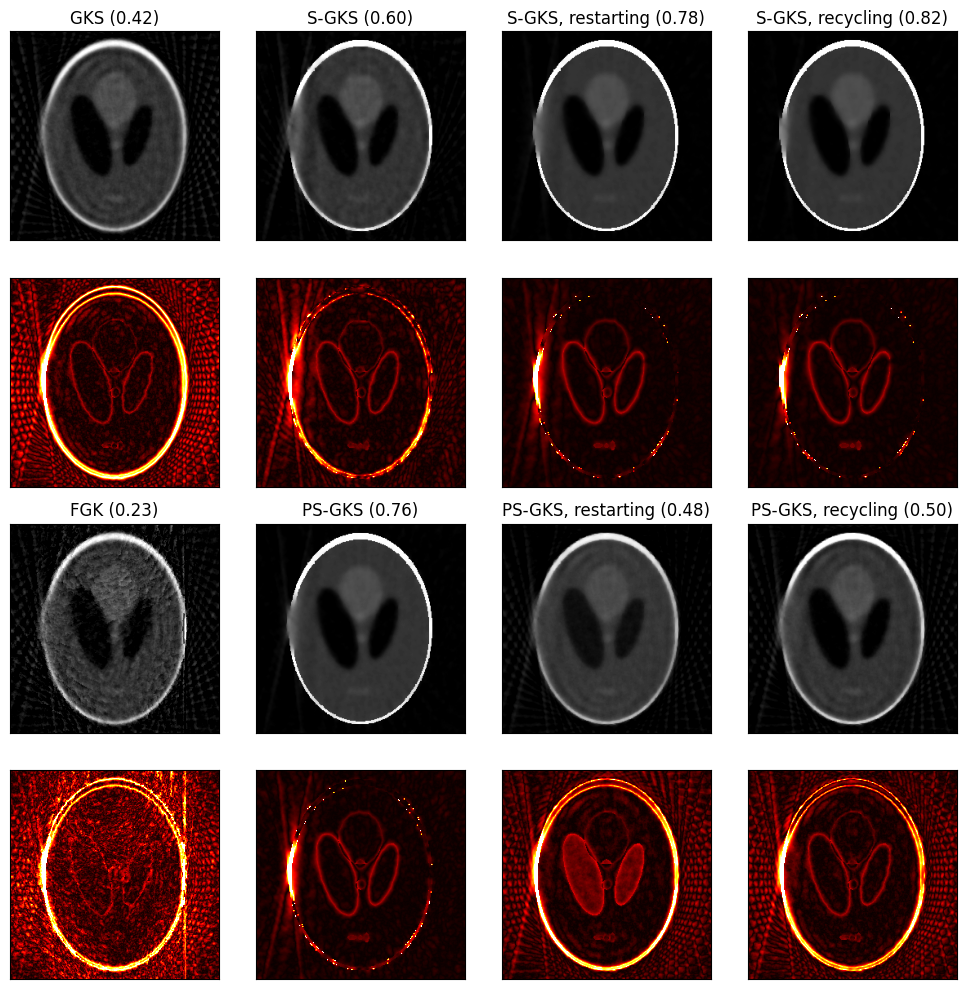

In [31]:
err_cmap = "hot"

vbound = 0.4
metric = "ssim_history"
ground_truth = x_true.copy()
b = noisy_signal.copy()

fig, axs = plt.subplots(4,4,figsize=(10,10))

# Observed
# perf_metric = structural_similarity( b.reshape(img_shape), ground_truth.reshape(img_shape), data_range=(np.amax(ground_truth) - np.amin(ground_truth) ), gaussian_weights=True, sigma=1.5, use_sample_covariance=False )
# axs[0,0].imshow(b.reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# axs[0,0].set_title(f"Data ({perf_metric:.2f})")
# axs[0,0].set_xticks([])
# axs[0,0].set_yticks([])

# axs[1,0].imshow(np.abs( b.reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[1,0].set_xticks([])
# axs[1,0].set_yticks([])


# V-GKS
axs[0,0].imshow(v_gks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = v_gks_data[metric][-1]
axs[0,0].set_title(f"GKS ({perf_metric:.2f})")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( v_gks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])

# FGK
axs[2,0].imshow(ias_fgk_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = ias_fgk_data[metric][-1]
axs[2,0].set_title(f"FGK ({perf_metric:.2f})")
axs[2,0].set_xticks([])
axs[2,0].set_yticks([])

axs[3,0].imshow(np.abs( ias_fgk_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,0].set_xticks([])
axs[3,0].set_yticks([])




# S-GKS
axs[0,1].imshow(ias_sgks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = ias_sgks_data[metric][-1]
axs[0,1].set_title(f"S-GKS ({perf_metric:.2f})")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( ias_sgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])



# PS-GKS
axs[2,1].imshow(ias_psgks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = ias_psgks_data[metric][-1]
axs[2,1].set_title(f"PS-GKS ({perf_metric:.2f})")
axs[2,1].set_xticks([])
axs[2,1].set_yticks([])

axs[3,1].imshow(np.abs( ias_psgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,1].set_xticks([])
axs[3,1].set_yticks([])




# S-GKS (restarted)
axs[0,2].imshow(ias_ressgks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = ias_ressgks_data[metric][-1]
axs[0,2].set_title(f"S-GKS, restarting ({perf_metric:.2f})")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( ias_ressgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])



# PS-GKS (restarted)
axs[2,2].imshow(ias_respsgks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = ias_respsgks_data[metric][-1]
axs[2,2].set_title(f"PS-GKS, restarting ({perf_metric:.2f})")
axs[2,2].set_xticks([])
axs[2,2].set_yticks([])

axs[3,2].imshow(np.abs( ias_respsgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,2].set_xticks([])
axs[3,2].set_yticks([])






# S-GKS (recycling)
axs[0,3].imshow(ias_recsgks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = ias_recsgks_data[metric][-1]
axs[0,3].set_title(f"S-GKS, recycling ({perf_metric:.2f})")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( ias_recsgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])



# PS-GKS (recycling)
axs[2,3].imshow(ias_recpsgks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = ias_recpsgks_data[metric][-1]
axs[2,3].set_title(f"PS-GKS, recycling ({perf_metric:.2f})")
axs[2,3].set_xticks([])
axs[2,3].set_yticks([])

axs[3,3].imshow(np.abs( ias_recpsgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,3].set_xticks([])
axs[3,3].set_yticks([])









# # PS-GKB
# axs[0,3].imshow(mm_psgkb_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# perf_metric = mm_psgkb_data[metric][-1]
# axs[0,3].set_title(f"PS-GKB ({perf_metric:.2f})")
# axs[0,3].set_xticks([])
# axs[0,3].set_yticks([])

# axs[1,3].imshow(np.abs( mm_psgkb_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[1,3].set_xticks([])
# axs[1,3].set_yticks([])



# # LSQR-I
# axs[2,1].imshow(mm_fgk2019I_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# perf_metric = mm_fgk2019I_data[metric][-1]
# axs[2,1].set_title(f"FLSQR-I ({perf_metric:.2f})")
# axs[2,1].set_xticks([])
# axs[2,1].set_yticks([])

# axs[3,1].imshow(np.abs( mm_fgk2019I_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[3,1].set_xticks([])
# axs[3,1].set_yticks([])



# # LSQR-R
# axs[2,2].imshow(mm_fgk2019R_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# perf_metric = mm_fgk2019R_data[metric][-1]
# axs[2,2].set_title(f"FLSQR-R ({perf_metric:.2f})")
# axs[2,2].set_xticks([])
# axs[2,2].set_yticks([])

# axs[3,2].imshow(np.abs( mm_fgk2019R_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[3,2].set_xticks([])
# axs[3,2].set_yticks([])


# # LSQR-W
# axs[2,3].imshow(mm_fgk2019W_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# perf_metric = mm_fgk2019W_data[metric][-1]
# axs[2,3].set_title(f"FLSQR-W ({perf_metric:.2f})")
# axs[2,3].set_xticks([])
# axs[2,3].set_yticks([])

# axs[3,3].imshow(np.abs( mm_fgk2019W_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[3,3].set_xticks([])
# axs[3,3].set_yticks([])




# # IRW-LSQR
# axs[2,4].imshow(mm_fgk2019IRW_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# perf_metric = mm_fgk2019IRW_data[metric][-1]
# axs[2,4].set_title(f"IRW-FLSQR ({perf_metric:.2f})")
# axs[2,4].set_xticks([])
# axs[2,4].set_yticks([])

# axs[3,4].imshow(np.abs( mm_fgk2019IRW_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[3,4].set_xticks([])
# axs[3,4].set_yticks([])


fig.tight_layout()

fig.savefig("2d_tomo_reconstructions_ias.png", dpi=250, bbox_inches=None)
fig.savefig("2d_tomo_ias.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

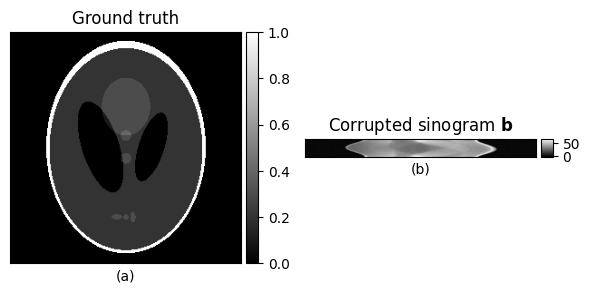

In [32]:
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Create a figure and a 2x2 grid of subplots
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(6, 6))

# Display data in each subplot manually with the 'YlGnBu_r' colormap and add a colorbar
im0 = axes[0].imshow(x_true.reshape((nx,ny)), cmap=CMAP)
axes[0].set_title('Ground truth')
#axes[0, 0].axis('off')
axes[0].set_xticks([])
axes[0].set_yticks([])
axes[0].set_xlabel("(a)")
divider = make_axes_locatable(axes[0])
cax0 = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im0, cax=cax0)

im1 = axes[1].imshow(b_noisy_shaped, cmap=CMAP)
axes[1].set_title('Corrupted sinogram $\\mathbf{b}$')
#axes[0, 1].axis('off')
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].set_xlabel("(b)")
divider = make_axes_locatable(axes[1])
cax1 = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im1, cax=cax1)

# im2 = axes[1, 0].imshow(np.clip(fbp_recon, a_min=0.0, a_max=None), cmap=CMAP)
# axes[1, 0].set_title('Filtered backprojection')
# # axes[1, 0].axis('off')
# axes[1,0].set_xticks([])
# axes[1,0].set_yticks([])
# axes[1,0].set_xlabel("(c)")
# divider = make_axes_locatable(axes[1, 0])
# cax2 = divider.append_axes("right", size="5%", pad=0.05)
# fig.colorbar(im2, cax=cax2)

# im3 = axes[1, 1].imshow(np.clip(x0.reshape((nx,ny)), a_min=0.0, a_max=None), cmap=CMAP, vmin=0, vmax=1)
# axes[1, 1].set_title('Tikhonov reconstruction')
# #axes[1, 1].axis('off')
# axes[1,1].set_xticks([])
# axes[1,1].set_yticks([])
# axes[1,1].set_xlabel("(d)")
# divider = make_axes_locatable(axes[1, 1])
# cax3 = divider.append_axes("right", size="5%", pad=0.05)
# fig.colorbar(im3, cax=cax3)

# Adjust the layout to make sure there's enough space between subplots
fig.tight_layout()
fig.savefig("tomo_data.png", dpi=250, bbox_inches=None)


# Display the figure
plt.show()


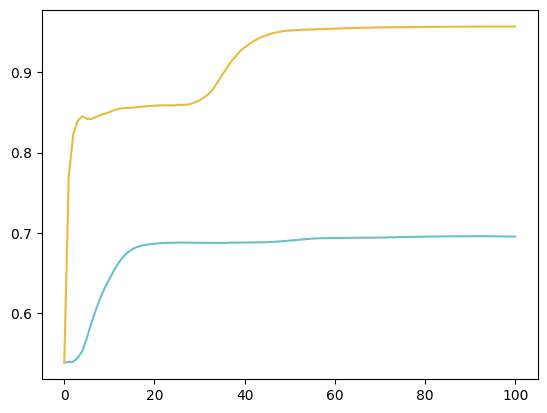

In [33]:
plt.plot( mm_sgks_data["gini_indices"], label="S-GKS")
plt.plot( mm_psgks_data["gini_indices"], label="PS-GKS")
plt.show()

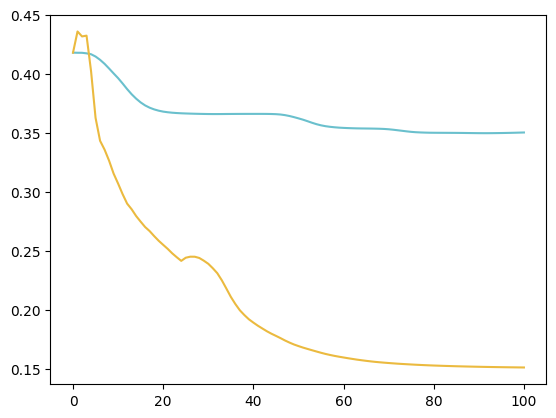

In [34]:
plt.plot( mm_sgks_data["rre_history"], label="S-GKS")
plt.plot( mm_psgks_data["rre_history"], label="PS-GKS")
plt.show()

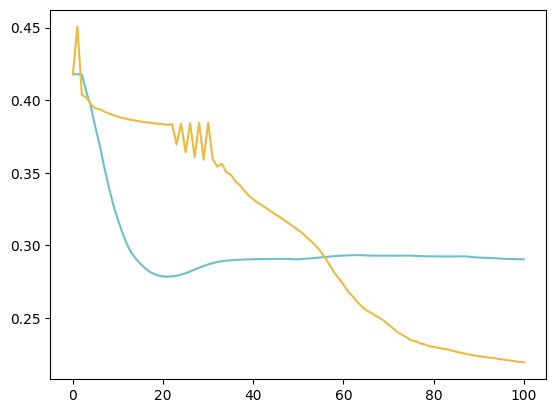

In [35]:
plt.plot( ias_sgks_data["rre_history"], label="S-GKS")
plt.plot( ias_psgks_data["rre_history"], label="PS-GKS")
plt.show()

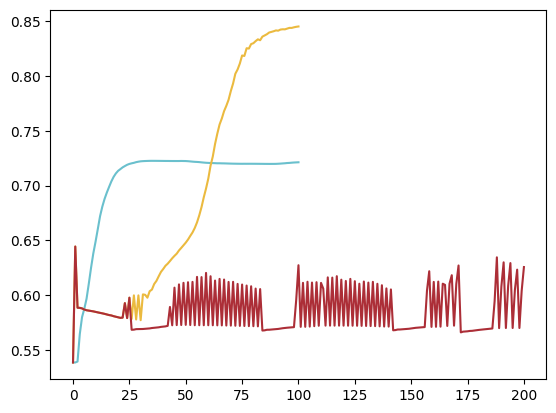

In [36]:
plt.plot( ias_sgks_data["gini_indices"], label="S-GKS")
plt.plot( ias_psgks_data["gini_indices"], label="PS-GKS")
plt.plot( ias_respsgks_data["gini_indices"], label="PS-GKS restarted")
plt.show()

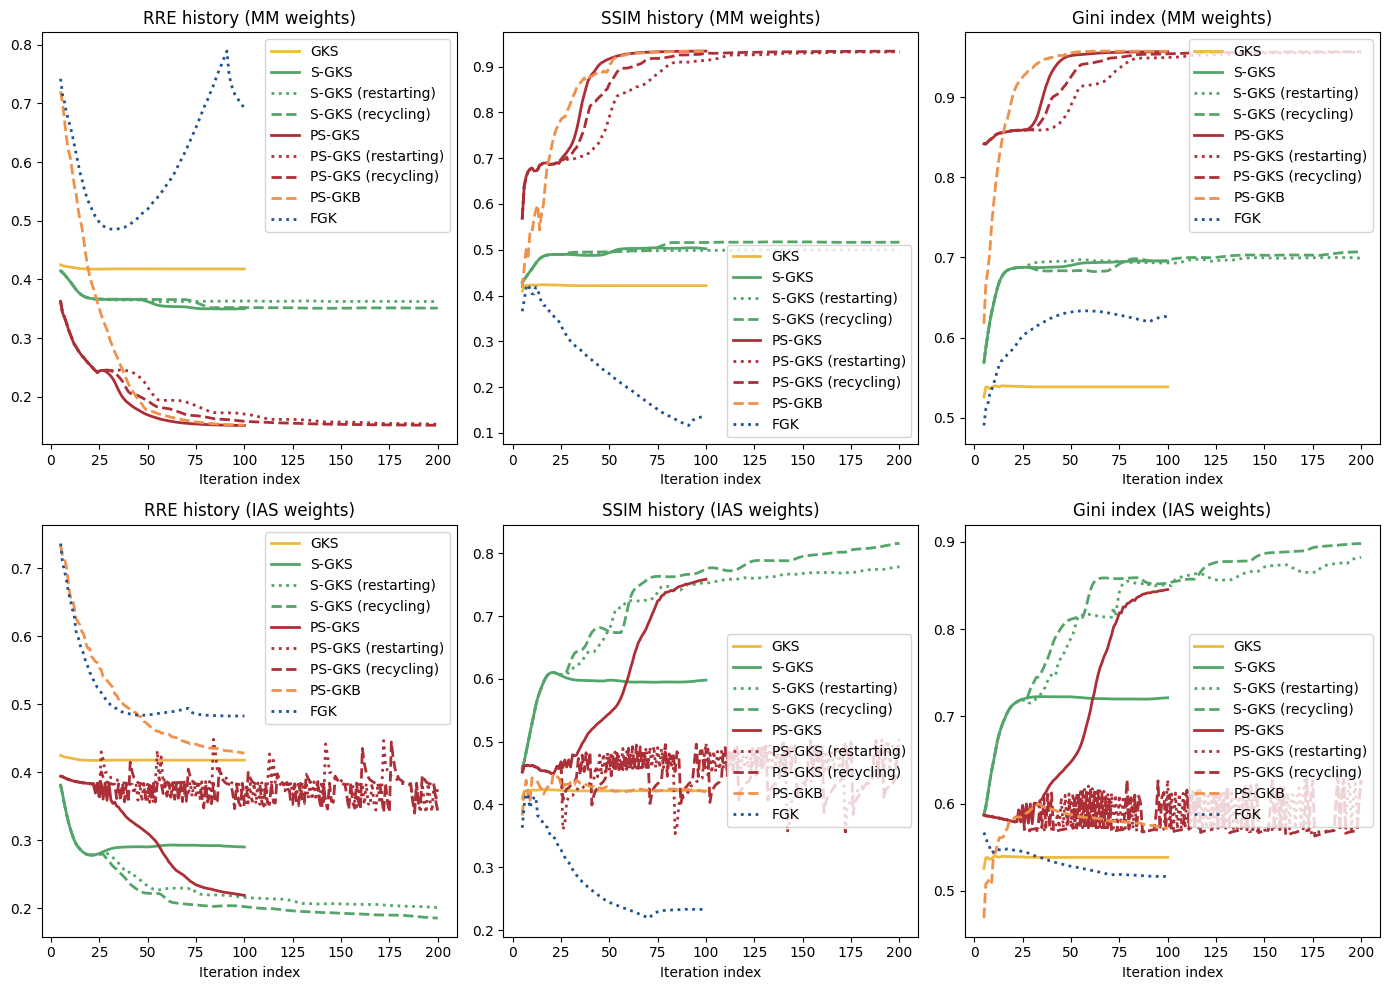

In [37]:
metric = "gini_indices"
#metric = "hoyer_indices"
# metric = "rre_history"
start_idx = 5
marker_size = 10.0
line_width = 2.0


method_lines = {
    "GKS": "solid",
    "S-GKS": "solid",
    "resS-GKS": "dotted",
    "recS-GKS": "dashed",
    "PS-GKS": "solid",
    "resPS-GKS": "dotted",
    "recPS-GKS": "dashed",
    "PS-GKB": "dashed",
    "FGK": "dotted",
    "FLSQR-I": "dotted",
    "FLSQR-R": "dashed",
    "FLSQR-W": "dashdot",
    "IRW-FLSQR": (0, (3, 1, 1, 1, 1, 1)),
}

fig, axs = plt.subplots(2,3,figsize=(14,10))


# First plot
plot_idx = (0,0)
plot_title = "RRE history (MM weights)"
metric = "rre_history"


method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
axs[plot_idx].plot( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "S-GKS (restarting)"
grid = [i for i in range(start_idx, len(mm_ressgks_data[metric]))]
axs[plot_idx].plot( grid, mm_ressgks_data[metric][start_idx:], color=method_colors["S-GKS"], ls="dotted", lw=line_width, label=method)


method = "S-GKS (recycling)"
grid = [i for i in range(start_idx, len(mm_recsgks_data[metric]))]
axs[plot_idx].plot( grid, mm_recsgks_data[metric][start_idx:], color=method_colors["S-GKS"], ls="dashed", lw=line_width, label=method)



method = "PS-GKS"
grid = [i for i in range(start_idx, len(mm_psgks_data[metric]))]
axs[plot_idx].plot( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "PS-GKS (restarting)"
grid = [i for i in range(start_idx, len(mm_respsgks_data[metric]))]
axs[plot_idx].plot( grid, mm_respsgks_data[metric][start_idx:], color=method_colors["PS-GKS"], ls="dotted", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_gkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "PS-GKS (recycling)"
grid = [i for i in range(start_idx, len(mm_recpsgks_data[metric]))]
axs[plot_idx].plot( grid, mm_recpsgks_data[metric][start_idx:], color=method_colors["PS-GKS"], ls="dashed", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_gkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)




method = "PS-GKB"
grid = [i for i in range(start_idx, len(mm_gkb_data[metric]))]
axs[plot_idx].plot( grid, mm_gkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_gkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)




method = "FGK"
grid = [i for i in range(start_idx, len(mm_fgk_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(mm_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "FLSQR-R"
# grid = [i for i in range(start_idx, len(mm_fgk2019R_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-W"
# grid = [i for i in range(start_idx, len(mm_fgk2019W_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)



# method = "FLSQR-I"
# grid = [i for i in range(start_idx, len(mm_fgk2019I_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019I_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_fgk2019I_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-R"
# grid = [i for i in range(start_idx, len(mm_fgk2019R_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)




axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)




# First plot
plot_idx = (1,0)
plot_title = "RRE history (IAS weights)"
metric = "rre_history"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(ias_sgks_data[metric]))]
axs[plot_idx].plot( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "S-GKS (restarting)"
grid = [i for i in range(start_idx, len(ias_ressgks_data[metric]))]
axs[plot_idx].plot( grid, ias_ressgks_data[metric][start_idx:], color=method_colors["S-GKS"], ls="dotted", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "S-GKS (recycling)"
grid = [i for i in range(start_idx, len(ias_recsgks_data[metric]))]
axs[plot_idx].plot( grid, ias_recsgks_data[metric][start_idx:], color=method_colors["S-GKS"], ls="dashed", lw=line_width, label=method)



method = "PS-GKS"
grid = [i for i in range(start_idx, len(ias_psgks_data[metric]))]
axs[plot_idx].plot( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "PS-GKS (restarting)"
grid = [i for i in range(start_idx, len(ias_respsgks_data[metric]))]
axs[plot_idx].plot( grid, ias_respsgks_data[metric][start_idx:], color=method_colors["PS-GKS"], ls="dotted", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "PS-GKS (recycling)"
grid = [i for i in range(start_idx, len(ias_recpsgks_data[metric]))]
axs[plot_idx].plot( grid, ias_recpsgks_data[metric][start_idx:], color=method_colors["PS-GKS"], ls="dashed", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



method = "PS-GKB"
grid = [i for i in range(start_idx, len(ias_gkb_data[metric]))]
axs[plot_idx].plot( grid, ias_gkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(ias_fgk_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(ias_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-R"
# grid = [i for i in range(start_idx, len(ias_fgk2019R_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-W"
# grid = [i for i in range(start_idx, len(ias_fgk2019W_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-I"
# grid = [i for i in range(start_idx, len(ias_fgk2019I_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019I_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_fgk2019I_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)









# First plot
plot_idx = (0,1)
plot_title = "SSIM history (MM weights)"
metric = "ssim_history"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
axs[plot_idx].plot( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "S-GKS (restarting)"
grid = [i for i in range(start_idx, len(mm_ressgks_data[metric]))]
axs[plot_idx].plot( grid, mm_ressgks_data[metric][start_idx:], color=method_colors["S-GKS"], ls="dotted", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "S-GKS (recycling)"
grid = [i for i in range(start_idx, len(mm_recsgks_data[metric]))]
axs[plot_idx].plot( grid, mm_recsgks_data[metric][start_idx:], color=method_colors["S-GKS"], ls="dashed", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS"
grid = [i for i in range(start_idx, len(mm_psgks_data[metric]))]
axs[plot_idx].plot( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS (restarting)"
grid = [i for i in range(start_idx, len(mm_respsgks_data[metric]))]
axs[plot_idx].plot( grid, mm_respsgks_data[metric][start_idx:], color=method_colors["PS-GKS"], ls="dotted", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "PS-GKS (recycling)"
grid = [i for i in range(start_idx, len(mm_recpsgks_data[metric]))]
axs[plot_idx].plot( grid, mm_recpsgks_data[metric][start_idx:], color=method_colors["PS-GKS"], ls="dashed", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



method = "PS-GKB"
grid = [i for i in range(start_idx, len(mm_gkb_data[metric]))]
axs[plot_idx].plot( grid, mm_gkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(mm_fgk_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(mm_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "FLSQR-R"
# grid = [i for i in range(start_idx, len(mm_fgk2019R_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-W"
# grid = [i for i in range(start_idx, len(mm_fgk2019W_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)






# First plot
plot_idx = (1,1)
plot_title = "SSIM history (IAS weights)"
metric = "ssim_history"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(ias_sgks_data[metric]))]
axs[plot_idx].plot( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "S-GKS (restarting)"
grid = [i for i in range(start_idx, len(ias_ressgks_data[metric]))]
axs[plot_idx].plot( grid, ias_ressgks_data[metric][start_idx:], color=method_colors["S-GKS"], ls="dotted", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "S-GKS (recycling)"
grid = [i for i in range(start_idx, len(ias_recsgks_data[metric]))]
axs[plot_idx].plot( grid, ias_recsgks_data[metric][start_idx:], color=method_colors["S-GKS"], ls="dashed", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "PS-GKS"
grid = [i for i in range(start_idx, len(ias_psgks_data[metric]))]
axs[plot_idx].plot( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS (restarting)"
grid = [i for i in range(start_idx, len(ias_respsgks_data[metric]))]
axs[plot_idx].plot( grid, ias_respsgks_data[metric][start_idx:], color=method_colors["PS-GKS"], ls="dotted", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "PS-GKS (recycling)"
grid = [i for i in range(start_idx, len(ias_recpsgks_data[metric]))]
axs[plot_idx].plot( grid, ias_recpsgks_data[metric][start_idx:], color=method_colors["PS-GKS"], ls="dashed", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



method = "PS-GKB"
grid = [i for i in range(start_idx, len(ias_gkb_data[metric]))]
axs[plot_idx].plot( grid, ias_gkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(ias_fgk_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(ias_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-R"
# grid = [i for i in range(start_idx, len(ias_fgk2019R_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-W"
# grid = [i for i in range(start_idx, len(ias_fgk2019W_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)












# First plot
plot_idx = (0,2)
plot_title = "Gini index (MM weights)"
metric = "gini_indices"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
axs[plot_idx].plot( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "S-GKS (restarting)"
grid = [i for i in range(start_idx, len(mm_ressgks_data[metric]))]
axs[plot_idx].plot( grid, mm_ressgks_data[metric][start_idx:], color=method_colors["S-GKS"], ls="dotted", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "S-GKS (recycling)"
grid = [i for i in range(start_idx, len(mm_recsgks_data[metric]))]
axs[plot_idx].plot( grid, mm_recsgks_data[metric][start_idx:], color=method_colors["S-GKS"], ls="dashed", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "PS-GKS"
grid = [i for i in range(start_idx, len(mm_psgks_data[metric]))]
axs[plot_idx].plot( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "PS-GKS (restarting)"
grid = [i for i in range(start_idx, len(mm_respsgks_data[metric]))]
axs[plot_idx].plot( grid, mm_respsgks_data[metric][start_idx:], color=method_colors["PS-GKS"], ls="dotted", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS (recycling)"
grid = [i for i in range(start_idx, len(mm_recpsgks_data[metric]))]
axs[plot_idx].plot( grid, mm_recpsgks_data[metric][start_idx:], color=method_colors["PS-GKS"], ls="dashed", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



method = "PS-GKB"
grid = [i for i in range(start_idx, len(mm_gkb_data[metric]))]
axs[plot_idx].plot( grid, mm_gkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(mm_fgk_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(mm_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "FLSQR-R"
# grid = [i for i in range(start_idx, len(mm_fgk2019R_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-W"
# grid = [i for i in range(start_idx, len(mm_fgk2019W_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)




axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)




# First plot
plot_idx = (1,2)
plot_title = "Gini index (IAS weights)"
metric = "gini_indices"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(ias_sgks_data[metric]))]
axs[plot_idx].plot( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "S-GKS (restarting)"
grid = [i for i in range(start_idx, len(ias_ressgks_data[metric]))]
axs[plot_idx].plot( grid, ias_ressgks_data[metric][start_idx:], color=method_colors["S-GKS"], ls="dotted", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "S-GKS (recycling)"
grid = [i for i in range(start_idx, len(ias_recsgks_data[metric]))]
axs[plot_idx].plot( grid, ias_recsgks_data[metric][start_idx:], color=method_colors["S-GKS"], ls="dashed", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "PS-GKS"
grid = [i for i in range(start_idx, len(ias_psgks_data[metric]))]
axs[plot_idx].plot( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS (restarting)"
grid = [i for i in range(start_idx, len(ias_respsgks_data[metric]))]
axs[plot_idx].plot( grid, ias_respsgks_data[metric][start_idx:], color=method_colors["PS-GKS"], ls="dotted", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS (recycling)"
grid = [i for i in range(start_idx, len(ias_recpsgks_data[metric]))]
axs[plot_idx].plot( grid, ias_recpsgks_data[metric][start_idx:], color=method_colors["PS-GKS"], ls="dashed", lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



method = "PS-GKB"
grid = [i for i in range(start_idx, len(ias_gkb_data[metric]))]
axs[plot_idx].plot( grid, ias_gkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(ias_fgk_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(ias_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)

# method = "FLSQR-R"
# grid = [i for i in range(start_idx, len(ias_fgk2019R_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)

# method = "FLSQR-W"
# grid = [i for i in range(start_idx, len(ias_fgk2019W_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)



axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)



fig.tight_layout()
fig.savefig("2d_tomo_performance", dpi=250, bbox_inches=None)
fig.savefig("2d_tomo_performance.eps", format="eps", dpi=250, bbox_inches=None)




plt.show()

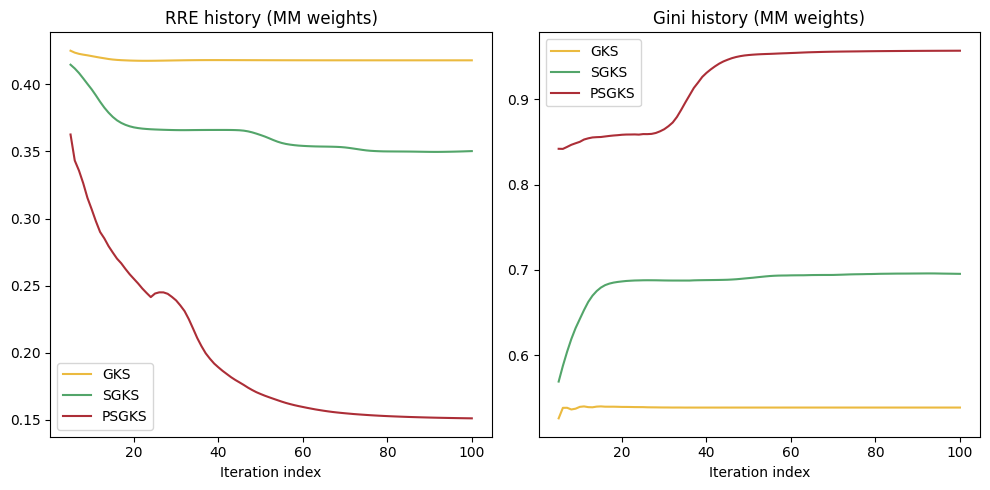

In [41]:
fig, axs = plt.subplots(1,2,figsize=(10,5))

start_idx = 5


metric = "rre_history"
grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
axs[0].plot(grid, v_gks_data[metric][start_idx:], color=method_colors["GKS"], label="GKS")
axs[0].plot(grid, mm_sgks_data[metric][start_idx:], color=method_colors["S-GKS"], label="SGKS")
axs[0].plot(grid, mm_psgks_data[metric][start_idx:], color=method_colors["PS-GKS"], label="PSGKS")
axs[0].set_title("RRE history (MM weights)")
axs[0].set_xlabel("Iteration index")
axs[0].legend()


metric = "gini_indices"
grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
axs[1].plot(grid, v_gks_data[metric][start_idx:], color=method_colors["GKS"], label="GKS")
axs[1].plot(grid, mm_sgks_data[metric][start_idx:], color=method_colors["S-GKS"], label="SGKS")
axs[1].plot(grid, mm_psgks_data[metric][start_idx:], color=method_colors["PS-GKS"], label="PSGKS")
axs[1].set_title("Gini history (MM weights)")
axs[1].set_xlabel("Iteration index")
axs[1].legend()

fig.tight_layout()

fig.savefig("mod_mm_2d_tomo_performance", dpi=250, bbox_inches=None)
fig.savefig("mod_mm_2d_tomo_performance.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()

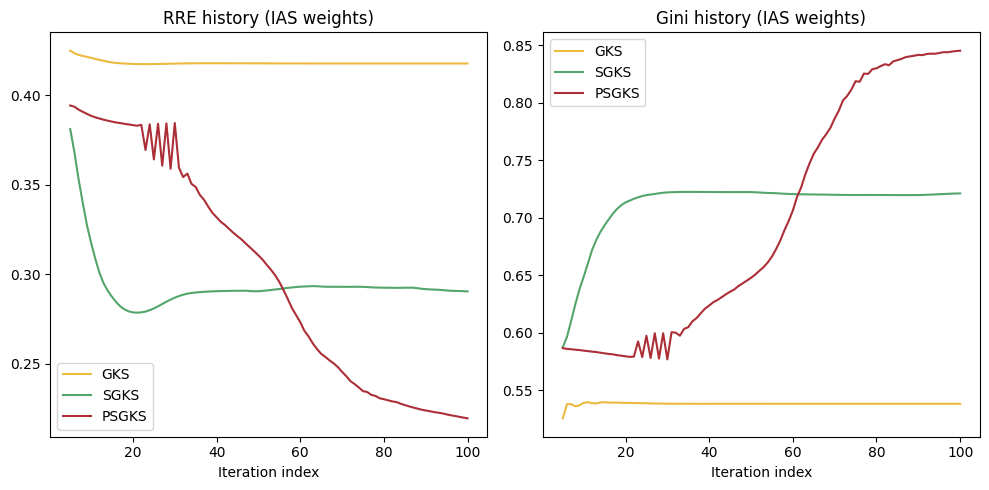

In [42]:
fig, axs = plt.subplots(1,2,figsize=(10,5))

start_idx = 5


metric = "rre_history"
grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
axs[0].plot(grid, v_gks_data[metric][start_idx:], color=method_colors["GKS"], label="GKS")
axs[0].plot(grid, ias_sgks_data[metric][start_idx:], color=method_colors["S-GKS"], label="SGKS")
axs[0].plot(grid, ias_psgks_data[metric][start_idx:], color=method_colors["PS-GKS"], label="PSGKS")
axs[0].set_title("RRE history (IAS weights)")
axs[0].set_xlabel("Iteration index")
axs[0].legend()


metric = "gini_indices"
grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
axs[1].plot(grid, v_gks_data[metric][start_idx:], color=method_colors["GKS"], label="GKS")
axs[1].plot(grid, ias_sgks_data[metric][start_idx:], color=method_colors["S-GKS"], label="SGKS")
axs[1].plot(grid, ias_psgks_data[metric][start_idx:], color=method_colors["PS-GKS"], label="PSGKS")
axs[1].set_title("Gini history (IAS weights)")
axs[1].set_xlabel("Iteration index")
axs[1].legend()

fig.tight_layout()

fig.savefig("mod_ias_2d_tomo_performance", dpi=250, bbox_inches=None)
fig.savefig("mod_ias_2d_tomo_performance.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()